In [21]:
GAMMA = 0.9    # Faktor diskonto
THETA = 0.1   # Batas perubahan nilai untuk berhenti
MDP = {
    "Rumah": [
        ("Jalan utama", "Terminal", 2),
        ("Jalan alternatif", "Taman", 3)
    ],

    "Terminal": [
        ("Naik bus", "Perpustakaan", 5),
        ("Jalan kaki", "Taman", 1)
    ],

    "Taman": [
        ("Ke halte", "Halte", 4),
        ("Ke perpustakaan", "Perpustakaan", 3)
    ],

    "Perpustakaan": [
        ("Ke kampus", "Kampus", 8)
    ],

    "Halte": [
        ("Naik bus ke kampus", "Kampus", 10),
        ("Ke perpustakaan", "Perpustakaan", 2)
    ],

    "Kampus": []
}


def nilai_aksi(V, reward, tujuan, gamma):
    """Reward langsung ditambah nilai masa depan yang didiskon."""
    return reward + gamma * V[tujuan]

def perbarui_nilai(mdp, V, gamma):
    """Satu iterasi: hitung nilai baru semua state dari nilai lama."""
    V_baru, delta = {}, 0.0
    for state, aksi_list in mdp.items():
        if not aksi_list:
            V_baru[state] = 0.0          # state terminal selalu bernilai 0
        else:
            V_baru[state] = max(         # nilai state = nilai aksi terbaik
                nilai_aksi(V, reward, tujuan, gamma)
                for nama, tujuan, reward in aksi_list
            )
        delta = max(delta, abs(V_baru[state] - V[state]))
    return V_baru, delta

def value_iteration(mdp, gamma, theta):
    """Ulangi pembaruan sampai perubahan terbesar < theta."""
    V = {s: 0.0 for s in mdp}            # nilai awal semua state = 0
    riwayat = [V.copy()]
    k = 0
    while True:
        V, delta = perbarui_nilai(mdp, V, gamma)
        k += 1
        riwayat.append(V.copy())
        if delta < theta:
            break
    return V, riwayat, k

def ambil_policy(mdp, V, gamma):
    """Pada tiap state, pilih aksi dengan nilai terbesar."""
    policy = {}
    for state, aksi_list in mdp.items():
        if aksi_list:
            terbaik = max(aksi_list, key=lambda a: nilai_aksi(V, a[2], a[1], gamma))
            policy[state] = terbaik[0]
    return policy

V_opt, riwayat, k = value_iteration(MDP, GAMMA, THETA)
policy_opt = ambil_policy(MDP, V_opt, GAMMA)

In [22]:
print("Nilai optimal:", V_opt)
print("Policy optimal:", policy_opt)
print("Jumlah iterasi:", k)
print("\nRiwayat nilai setiap iterasi:")
for i, nilai in enumerate(riwayat):
    print(f"Iterasi {i}: {nilai}")

Nilai optimal: {'Rumah': 14.700000000000001, 'Terminal': 12.700000000000001, 'Taman': 13.0, 'Perpustakaan': 8.0, 'Halte': 10.0, 'Kampus': 0.0}
Policy optimal: {'Rumah': 'Jalan alternatif', 'Terminal': 'Jalan kaki', 'Taman': 'Ke halte', 'Perpustakaan': 'Ke kampus', 'Halte': 'Naik bus ke kampus'}
Jumlah iterasi: 4

Riwayat nilai setiap iterasi:
Iterasi 0: {'Rumah': 0.0, 'Terminal': 0.0, 'Taman': 0.0, 'Perpustakaan': 0.0, 'Halte': 0.0, 'Kampus': 0.0}
Iterasi 1: {'Rumah': 3.0, 'Terminal': 5.0, 'Taman': 4.0, 'Perpustakaan': 8.0, 'Halte': 10.0, 'Kampus': 0.0}
Iterasi 2: {'Rumah': 6.6, 'Terminal': 12.2, 'Taman': 13.0, 'Perpustakaan': 8.0, 'Halte': 10.0, 'Kampus': 0.0}
Iterasi 3: {'Rumah': 14.700000000000001, 'Terminal': 12.700000000000001, 'Taman': 13.0, 'Perpustakaan': 8.0, 'Halte': 10.0, 'Kampus': 0.0}
Iterasi 4: {'Rumah': 14.700000000000001, 'Terminal': 12.700000000000001, 'Taman': 13.0, 'Perpustakaan': 8.0, 'Halte': 10.0, 'Kampus': 0.0}


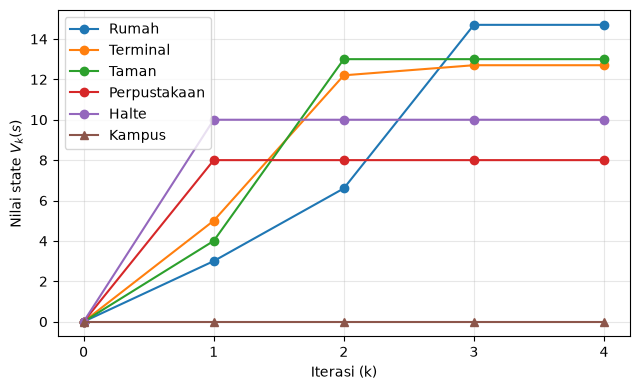

In [28]:
import matplotlib.pyplot as plt

iterasi = list(range(len(riwayat)))
plt.figure(figsize=(6.5, 4))
for state, penanda in [("Rumah", "o"), ("Terminal", "o"), ("Taman", "o"),("Perpustakaan", "o"),("Halte", "o"), ("Kampus", "^")]:
    plt.plot(iterasi, [v[state] for v in riwayat], marker=penanda, label=state)
plt.xlabel("Iterasi (k)")
plt.ylabel(r"Nilai state $V_k(s)$")
plt.xticks(iterasi)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()